# Laborator la obiectul: Rețele neurale și învățare profundă

# Lucrarea de laborator nr. 2:
Crearea unei rețele neuronale convoluționale (CNN) pentru
clasificarea sau recunoașterea imaginilor

## Scopul lucrării :
Înțelegerea straturilor de Convoluție, Pooling și Padding
necesari creării unei CNN. Antrenarea rețelei și validarea rezultatelor.

# A efectuat: Pleșu Cătălin
# A verificat: Mariana Rusu

# [Dataset : Wild Animals](https://www.kaggle.com/datasets/vishweshsalodkar/wild-animals)

**Pasul 1.** Citirea bibliotecilor necesare și vizualizarea informației despre mapa cu imagini

In [131]:
from sklearn.model_selection import train_test_split
from tqdm import tqdm
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
import pathlib
import tensorflow as tf
from sklearn.preprocessing import LabelEncoder

In [132]:
# # Download the dataset using kagglehub
# dataset_path = kagglehub.dataset_download("vishweshsalodkar/wild-animals")
# print("Path to dataset files:", dataset_path)
# dataset_path = os.path.join(dataset_path, 'Animals')

In [133]:
# # Download the dataset using kagglehub
# dataset_path = kagglehub.dataset_download("nikolasgegenava/sneakers-classification")
# print("Path to dataset files:", dataset_path)
# dataset_path = os.path.join(dataset_path, 'sneakers-dataset/sneakers-dataset')

In [134]:
# Download the dataset using kagglehub
dataset_path = kagglehub.dataset_download("muratkokludataset/pistachio-image-dataset")
print("Path to dataset files:", dataset_path)
dataset_path = os.path.join(dataset_path, 'Pistachio_Image_Dataset/Pistachio_Image_Dataset')
# !ls /root/.cache/kagglehub/datasets/muratkokludataset/pistachio-image-dataset/versions/1/Pistachio_Image_Dataset/Pistachio_Image_Dataset

Path to dataset files: /kaggle/input/pistachio-image-dataset


In [135]:
# define image size and batch size
IMG_SIZE = 124
BATCH_SIZE = 128

In [136]:
# 1. List all directories in dataset_path
try:
    all_items = [d for d in os.listdir(dataset_path) if os.path.isdir(os.path.join(dataset_path, d))]
    NUM_CLASSES = len(all_items)
except FileNotFoundError:
    print(f"Error: The dataset path '{dataset_path}' was not found.")
else:
    directories = [item for item in all_items if os.path.isdir(os.path.join(dataset_path, item))]

    # 2. For each directory, count and display the number of items
    for folder_name in directories:
        folder_path = os.path.join(dataset_path, folder_name)
        num_items = len(os.listdir(folder_path))
        print(f"The directory '{folder_name}' contains {num_items} items.")

print(f"Num Classes: {NUM_CLASSES}")

The directory 'Kirmizi_Pistachio' contains 1232 items.
The directory 'Siirt_Pistachio' contains 916 items.
Num Classes: 2


In [137]:
DataPath = pathlib.Path(dataset_path)
all_paths = DataPath.glob("*/*.j*g") # aici avem si jpg si jpeg
all_paths

<generator object Path.glob at 0x7c48af3109d0>

**Pasul 2.**  Citirea primelor 10 imagini din fișie

In [138]:
all_paths = list(all_paths)
print(len(all_paths))
all_paths[:5]

2148


[PosixPath('/kaggle/input/pistachio-image-dataset/Pistachio_Image_Dataset/Pistachio_Image_Dataset/Kirmizi_Pistachio/kirmizi 1109.jpg'),
 PosixPath('/kaggle/input/pistachio-image-dataset/Pistachio_Image_Dataset/Pistachio_Image_Dataset/Kirmizi_Pistachio/kirmizi (10).jpg'),
 PosixPath('/kaggle/input/pistachio-image-dataset/Pistachio_Image_Dataset/Pistachio_Image_Dataset/Kirmizi_Pistachio/kirmizi 97.jpg'),
 PosixPath('/kaggle/input/pistachio-image-dataset/Pistachio_Image_Dataset/Pistachio_Image_Dataset/Kirmizi_Pistachio/kirmizi 475.jpg'),
 PosixPath('/kaggle/input/pistachio-image-dataset/Pistachio_Image_Dataset/Pistachio_Image_Dataset/Kirmizi_Pistachio/kirmizi 29.jpg')]

In [139]:
all_paths = list(map(lambda x : str(x), all_paths))
all_paths[:5]

['/kaggle/input/pistachio-image-dataset/Pistachio_Image_Dataset/Pistachio_Image_Dataset/Kirmizi_Pistachio/kirmizi 1109.jpg',
 '/kaggle/input/pistachio-image-dataset/Pistachio_Image_Dataset/Pistachio_Image_Dataset/Kirmizi_Pistachio/kirmizi (10).jpg',
 '/kaggle/input/pistachio-image-dataset/Pistachio_Image_Dataset/Pistachio_Image_Dataset/Kirmizi_Pistachio/kirmizi 97.jpg',
 '/kaggle/input/pistachio-image-dataset/Pistachio_Image_Dataset/Pistachio_Image_Dataset/Kirmizi_Pistachio/kirmizi 475.jpg',
 '/kaggle/input/pistachio-image-dataset/Pistachio_Image_Dataset/Pistachio_Image_Dataset/Kirmizi_Pistachio/kirmizi 29.jpg']

**Pasul 3.** Amestecarea imaginilor în fișier cu scopul evitării antrenării rețelei doar pe un anumit
tip de imagini :

In [140]:
from random import shuffle

shuffle(all_paths)
print(len(all_paths))
all_paths[:5]

2148


['/kaggle/input/pistachio-image-dataset/Pistachio_Image_Dataset/Pistachio_Image_Dataset/Kirmizi_Pistachio/kirmizi 449.jpg',
 '/kaggle/input/pistachio-image-dataset/Pistachio_Image_Dataset/Pistachio_Image_Dataset/Kirmizi_Pistachio/kirmizi 280.jpg',
 '/kaggle/input/pistachio-image-dataset/Pistachio_Image_Dataset/Pistachio_Image_Dataset/Siirt_Pistachio/siirt 566.jpg',
 '/kaggle/input/pistachio-image-dataset/Pistachio_Image_Dataset/Pistachio_Image_Dataset/Kirmizi_Pistachio/kirmizi 1096.jpg',
 '/kaggle/input/pistachio-image-dataset/Pistachio_Image_Dataset/Pistachio_Image_Dataset/Siirt_Pistachio/siirt 214.jpg']

**Pasul 4.** Decodarea imaginilor :

In [141]:
def FilterValidImages(all_paths):
    new_all_paths = []
    for path in tqdm(all_paths):
        try:
            image = tf.io.read_file(path)
            image = tf.io.decode_jpeg(image, channels = 3)
        except:
            continue
        new_all_paths.append(path)
    return new_all_paths

all_paths = FilterValidImages(all_paths)
all_paths[:5]

100%|██████████| 2148/2148 [00:04<00:00, 520.14it/s]


['/kaggle/input/pistachio-image-dataset/Pistachio_Image_Dataset/Pistachio_Image_Dataset/Kirmizi_Pistachio/kirmizi 449.jpg',
 '/kaggle/input/pistachio-image-dataset/Pistachio_Image_Dataset/Pistachio_Image_Dataset/Kirmizi_Pistachio/kirmizi 280.jpg',
 '/kaggle/input/pistachio-image-dataset/Pistachio_Image_Dataset/Pistachio_Image_Dataset/Siirt_Pistachio/siirt 566.jpg',
 '/kaggle/input/pistachio-image-dataset/Pistachio_Image_Dataset/Pistachio_Image_Dataset/Kirmizi_Pistachio/kirmizi 1096.jpg',
 '/kaggle/input/pistachio-image-dataset/Pistachio_Image_Dataset/Pistachio_Image_Dataset/Siirt_Pistachio/siirt 214.jpg']

**Pasul 5.** Obținerea etichetelor și transformarea lor în 0 și 1

In [142]:
def get_label(image_path):
    return image_path.split("/")[-2]

all_labels = list(map(lambda x : get_label(x), all_paths))
all_labels[:10]

['Kirmizi_Pistachio',
 'Kirmizi_Pistachio',
 'Siirt_Pistachio',
 'Kirmizi_Pistachio',
 'Siirt_Pistachio',
 'Siirt_Pistachio',
 'Kirmizi_Pistachio',
 'Kirmizi_Pistachio',
 'Kirmizi_Pistachio',
 'Kirmizi_Pistachio']

In [143]:
# from sklearn.preprocessing import LabelEncoder

Le = LabelEncoder()
all_labels = Le.fit_transform(all_labels)

all_labels[:10]

array([0, 0, 1, 0, 1, 1, 0, 0, 0, 0])

In [144]:
# Din interes sportiv vom vedea ce numere au primit fiecare clasa
label_mapping = dict(zip(Le.classes_, Le.transform(Le.classes_)))
for label, encoded in label_mapping.items():
    print(f"{encoded} -> {label}")

0 -> Kirmizi_Pistachio
1 -> Siirt_Pistachio


**Pasul 6.** Crearea setului de antrenament

In [145]:
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical # For one-hot encoding

# --- Split data ---
Train_paths, Val_paths, Train_labels, Val_labels = train_test_split(all_paths, all_labels, test_size=0.2, random_state=42)

# --- One-hot encode labels ---
Train_labels_onehot = to_categorical(Train_labels, num_classes=NUM_CLASSES)
Val_labels_onehot = to_categorical(Val_labels, num_classes=NUM_CLASSES)

In [146]:
Train_paths[:5], Train_labels[:5]

(['/kaggle/input/pistachio-image-dataset/Pistachio_Image_Dataset/Pistachio_Image_Dataset/Siirt_Pistachio/siirt 133.jpg',
  '/kaggle/input/pistachio-image-dataset/Pistachio_Image_Dataset/Pistachio_Image_Dataset/Siirt_Pistachio/siirt 388.jpg',
  '/kaggle/input/pistachio-image-dataset/Pistachio_Image_Dataset/Pistachio_Image_Dataset/Kirmizi_Pistachio/kirmizi 490.jpg',
  '/kaggle/input/pistachio-image-dataset/Pistachio_Image_Dataset/Pistachio_Image_Dataset/Kirmizi_Pistachio/kirmizi 71.jpg',
  '/kaggle/input/pistachio-image-dataset/Pistachio_Image_Dataset/Pistachio_Image_Dataset/Siirt_Pistachio/siirt 784.jpg'],
 array([1, 1, 0, 0, 1]))

In [147]:
def loadImage(image, label):
    image = tf.io.read_file(image)
    image = tf.io.decode_jpeg(image, channels=3)

    # Check if image is loaded correctly
    if tf.reduce_all(tf.equal(image, 0)):  # If image is all zeros (black)
        print(f"Warning: Image {image} seems to be empty or black.")

    return image, label

In [148]:
# # define image size and batch size
# IMG_SIZE = 224
# BATCH_SIZE = 128

In [149]:
# Create a Tensorflow Data Object
AUTOTUNE = tf.data.experimental.AUTOTUNE

def resize(image):
    return tf.image.resize(image, [IMG_SIZE, IMG_SIZE])

def data_augmentation(image):
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_brightness(image, max_delta=0.1)
    return image

def get_dataset(paths, labels, train=True):
    image_paths = tf.convert_to_tensor(paths)
    labels = tf.convert_to_tensor(labels)

    image_dataset = tf.data.Dataset.from_tensor_slices(image_paths)
    label_dataset = tf.data.Dataset.from_tensor_slices(labels)

    dataset = tf.data.Dataset.zip((image_dataset, label_dataset))
    dataset = dataset.map(lambda image, label: loadImage(image, label))
    dataset = dataset.map(lambda image, label: (resize(image), label), num_parallel_calls=AUTOTUNE)
    dataset = dataset.shuffle(1000)
    dataset = dataset.batch(BATCH_SIZE)

    if train:
        dataset = dataset.map(lambda image, label: (data_augmentation(image), label), num_parallel_calls=AUTOTUNE)
        dataset = dataset.repeat()

    return dataset

In [150]:
# Creating Train Dataset object and Verifying it
%time train_dataset = get_dataset(Train_paths, Train_labels)

train_dataset

image, label = next(iter(train_dataset))
print(image.shape)
print(label.shape)

CPU times: user 58.5 ms, sys: 0 ns, total: 58.5 ms
Wall time: 58.2 ms
(128, 124, 124, 3)
(128,)


**Pasul 7.** Vizualizarea a câte un exemplu din fiecare clasă : cat, dog (din setul de antrenament) pentru a ne asigura că este citit corect

In [151]:
import matplotlib.pyplot as plt
import tensorflow as tf

def display_image_grid(dataset, rows=3, cols=3):
    """
    Displays a grid of images from the provided dataset.

    Parameters:
    dataset (iterable): The dataset from which images will be taken.
    rows (int): Number of rows in the grid.
    cols (int): Number of columns in the grid.
    """
    # Create a figure to display the images
    fig, axes = plt.subplots(rows, cols, figsize=(10, 8))

    # Loop through the rows and columns to display images
    for i in range(rows):
        for j in range(cols):
            ax = axes[i, j]  # Accessing each subplot axis
            image, label = next(iter(dataset))  # Get next image and label

            # Convert the image to NumPy array if it's an EagerTensor
            image = image[0].numpy()  # If the image is a batch, we select the first one

            # Get min and max values
            image_min = image.min()
            image_max = image.max()

            # Avoid division by zero (constant image)
            if image_max == image_min:
                print(f"Image {i * cols + j} is constant, skipping scaling.")
                image = image / 255.0  # Normalize to [0, 1]
            else:
                # Normalize the image to [0, 1]
                image = (image - image_min) / (image_max - image_min)

            ax.imshow(image)  # Display the image
            ax.set_title(f"Label: {Le.inverse_transform(label)[0]}")  # Set title with label
            ax.axis('off')  # Hide axes

    plt.tight_layout()  # Adjust spacing between images
    plt.show()

# Example call:
# display_image_grid(train_dataset)


In [152]:
%time val_dataset = get_dataset(Val_paths, Val_labels, train = False)

image, label = next(iter(val_dataset))
print(image.shape)
print(label.shape)

CPU times: user 88.9 ms, sys: 8.85 ms, total: 97.7 ms
Wall time: 90.6 ms
(128, 124, 124, 3)
(128,)


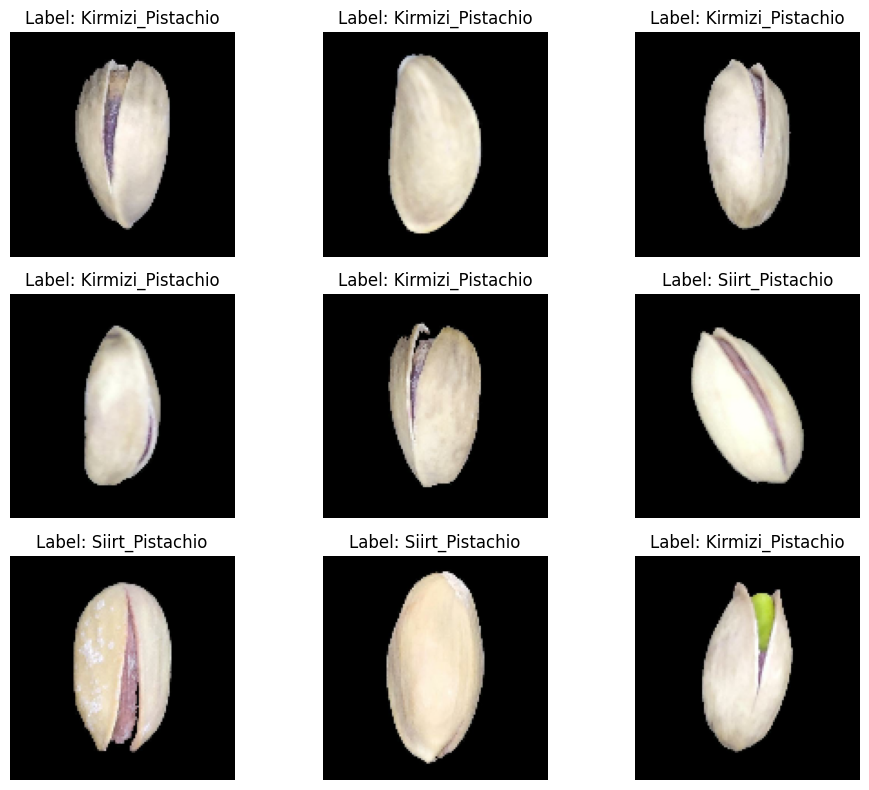

In [153]:
display_image_grid(val_dataset)

**Pasul 8.** Crearea modelului rețelei neuronale convoluționale:

In [154]:
# Model part
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Activation, Conv2D, MaxPooling2D, Flatten, Dropout, BatchNormalization, GlobalMaxPool2D


model = Sequential()
#Block 1
model.add(Conv2D(input_shape=(IMG_SIZE, IMG_SIZE, 3), padding='same', filters=32, kernel_size=(7,7)))
model.add(Activation('relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.2))

#Block 2
model.add(Conv2D(filters=64, padding='valid', kernel_size=(5,5)))
model.add(Activation('relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.2))

#Block 3
model.add(Conv2D(filters=128, padding='valid', kernel_size=(3,3)))
model.add(Activation('relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D())
model.add(Dropout(0.2))

#Block 4
model.add(Conv2D(filters=256, padding='valid', kernel_size=(3,3)))
model.add(Activation('relu'))
model.add(BatchNormalization())
model.add(Conv2D(filters=256, kernel_size=(3, 3)))
model.add(Activation('relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Dropout(0.2))
model.add(GlobalMaxPool2D())
model.add(Dense(units=256))
model.add(Activation('relu'))
model.add(Dropout(0.2))

if NUM_CLASSES == 2:
  model.add(Dense(units=2))
  model.add(Activation('sigmoid'))
else:
  model.add(Dense(units=NUM_CLASSES)) # Changed units to NUM_CLASSES
  model.add(Activation('softmax')) # Changed activation to softmax


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


**Pasul 9.** Vizualizare informații despre modelul creat

In [155]:
print(model.summary())

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_35 (Conv2D)              │ (None, 124, 124, 32)   │         4,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_47 (Activation)      │ (None, 124, 124, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_35          │ (None, 124, 124, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_28 (MaxPooling2D) │ (None, 62, 62, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_35 (Dropout)            │ (None, 62, 62, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_36 (Conv2D)              │ (None, 58, 58, 64)     │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_48 (Activation)      │ (None, 58, 58, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_36          │ (None, 58, 58, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_29 (MaxPooling2D) │ (None, 29, 29, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_36 (Dropout)            │ (None, 29, 29, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_37 (Conv2D)              │ (None, 27, 27, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_49 (Activation)      │ (None, 27, 27, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_37          │ (None, 27, 27, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_30 (MaxPooling2D) │ (None, 13, 13, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_37 (Dropout)            │ (None, 13, 13, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_38 (Conv2D)              │ (None, 11, 11, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_50 (Activation)      │ (None, 11, 11, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_38          │ (None, 11, 11, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_39 (Conv2D)              │ (None, 9, 9, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_51 (Activation)      │ (None, 9, 9, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_39          │ (None, 9, 9, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_31 (MaxPooling2D) │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 1,084,354 (4.14 MB)

 Trainable params: 1,082,882 (4.13 MB)

 Non-trainable params: 1,472 (5.75 KB)

None


**Pasul 10.** Compilare și antrenarea modelului

In [185]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Activation
from tensorflow.keras.utils import to_categorical
import numpy as np
from tensorflow.keras.utils import to_categorical

train_dataset = get_dataset(Train_paths, Train_labels_onehot, train=True)
val_dataset = get_dataset(Val_paths, Val_labels_onehot, train=False)

# Compute steps
steps_per_epoch = np.ceil(len(Train_paths) / BATCH_SIZE).astype(int)

class StopOnValLoss(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        val_loss = logs.get('val_loss')
        val_accuracy = logs.get('val_accuracy')
        if (val_loss is not None and val_loss < 0.25) or (val_accuracy is not None and val_accuracy >= 0.925):
            print(f"\nStopping training: val_loss < 0.1 at epoch {epoch+1}")
            self.model.stop_training = True


loss_fn = 'binary_crossentropy' if NUM_CLASSES == 2 else 'categorical_crossentropy'
# Compile model
model.compile(
    loss=loss_fn,
    optimizer='adam',
    metrics=['accuracy']
)

# Train
history = model.fit(
    train_dataset,
    epochs=30,
    steps_per_epoch=steps_per_epoch,
    validation_data=val_dataset,
    callbacks=[StopOnValLoss()]
)

print("Training finished")

Epoch 1/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 24s 874ms/step - accuracy: 0.9933 - loss: 0.0152 - val_accuracy: 0.9000 - val_loss: 0.4986
Epoch 2/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 3s 201ms/step - accuracy: 0.9961 - loss: 0.0114 - val_accuracy: 0.8488 - val_loss: 0.8077
Epoch 3/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 4s 259ms/step - accuracy: 0.9903 - loss: 0.0312 - val_accuracy: 0.8581 - val_loss: 0.7456
Epoch 4/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 3s 204ms/step - accuracy: 0.9947 - loss: 0.0186 - val_accuracy: 0.9116 - val_loss: 0.4145
Epoch 5/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 3s 201ms/step - accuracy: 0.9944 - loss: 0.0227 - val_accuracy: 0.8326 - val_loss: 0.7715
Epoch 6/30
13/14 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step - accuracy: 0.9919 - loss: 0.0227
Stopping training: val_loss < 0.1 at epoch 6
14/14 ━━━━━━━━━━━━━━━━━━━━ 3s 200ms/step - accuracy: 0.9920 - loss: 0.0225 - val_accuracy: 0.9256 - val_loss: 0.2662
Training finished


In [186]:
# import tensorflow as tf
# from google.colab import drive
# # Mount Google Drive
# drive.mount('/content/drive')

# # Or load an existing model:
# # model = tf.keras.models.load_model('your_model_path')

# # Define the path where you want to save the model in your Google Drive
# save_path = '/content/drive/MyDrive/lab2_cnn.keras' # Or use '.keras' format

# # Save the entire model as a `.keras` zip archive.
# model.save(save_path)

# print(f"Model saved to: {save_path}")

**Pasul 11.** Evaluarea modelului

In [187]:
# Evaluating the Loaded model
loss, acc = model.evaluate(val_dataset)

print("Testing Acc:", acc)
print("Testing Loss:", loss)

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.9301 - loss: 0.2641
Testing Acc: 0.9255813956260681
Testing Loss: 0.2661892771720886


In [188]:
from sklearn.metrics import confusion_matrix, classification_report

# Get predictions on the validation set
predictions = model.predict(val_dataset)  # Output is usually probabilities
predicted_labels = np.argmax(predictions, axis=1)  # Convert probabilities to class labels

# Get true labels from the validation set (this might require adapting based on how your val_dataset is structured)
true_labels = np.concatenate([y for x, y in val_dataset], axis=0)
true_labels = np.argmax(true_labels, axis=1)

print("Confusion Matrix:\n", confusion_matrix(true_labels, predicted_labels))
print("\nClassification Report:\n", classification_report(true_labels, predicted_labels))

4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 194ms/step
Confusion Matrix:
 [[122 121]
 [109  78]]

Classification Report:
               precision    recall  f1-score   support

           0       0.53      0.50      0.51       243
           1       0.39      0.42      0.40       187

    accuracy                           0.47       430
   macro avg       0.46      0.46      0.46       430
weighted avg       0.47      0.47      0.47       430



# Concluzii
Am creat un model CNN care este capabil să identifice două tipuri de orez. Modelul nu este bun, nici chiar satisfăcător, dar nu am putut antrena un model mai bun.

În schimb, fișierul este structurat în așa mod încât poate încărca orice dataset de pe Kaggle și să antreneze modelul, deși un model destul de nereușit.